# SMC WR population

Assuming $Z_\mathrm{SMC}=0.2Z_\odot$.

In [1]:
from posydon.utils.common_functions import convert_metallicity_to_string, orbital_separation_from_period
import matplotlib.pyplot as plt
import numpy as np

from cmap import Colormap
import pickle
from pathlib import Path
from tqdm import tqdm

# custom helper scripts
from helper_functions import calc_Teff, classify_WR_type

tol_vibrant = Colormap('tol:vibrant')(np.linspace(0, 1, 7))

In [2]:
data_folder = Path('/Users/max/Documents/projects/WR_population/data/optical_depth/')
metallicity = 0.2
met_str = convert_metallicity_to_string(metallicity)
file_path = data_folder / f'WR_phases_Z{met_str}_Zsun.pkl'
with open(file_path, 'rb') as f:
    data = pickle.load(f)
    
S1_WR_data = data['S1_WR_data']
S2_WR_data = data['S2_WR_data']


In [3]:
# hydrogen-poor/free stars

WR_types = []
time_array = []
weight_array = []
state_array = []
key_array = []
star_array = []  # Track whether entry is from S1 or S2
period_array = []
separation_array = []
Teff_array = []
L_array = []
optical_depth_array = []
surface_H_array = []
surface_He_array = []
mass_array = []
mass_companion_array = []
radius_array = []
Mdot_array = []
companion_array = []
S1_state_array = []
surface_C = []
optical_depth = []

for key in tqdm(S1_WR_data):
    data = S1_WR_data[key]['data']
    weights = S1_WR_data[key]['weights']
    optical_depth_array.extend(S1_WR_data[key]['optical_depth'])
    
    surface_H_array.extend(data['S1_surface_h1'].values)
    surface_He_array.extend(data['S1_surface_he4'].values)
    Teff = 10**calc_Teff(data['S1_log_L'], data['S1_log_R'])
         
    time_array.extend(data['time'].values)
    weight_array.extend(weights)
    state_array.extend(data['state'].values)
    S1_state_array.extend(data['S1_state'].values)
    key_array.extend([key] * len(data))
    star_array.extend(['S1'] * len(data))  # Mark as S1
    Teff_array.extend(Teff)
    L_array.extend(10**data['S1_log_L'].values)
    mass_array.extend(data['S1_mass'].values)
    mass_companion_array.extend(data['S2_mass'].values)
    radius_array.extend(10**data['S1_log_R'].values)
    Mdot_array.extend(10**data['S1_lg_mdot'].values)
    companion_array.extend(data['S2_state'].values)
    
    period_array.extend(data['orbital_period'].values)
    sep = orbital_separation_from_period(data['orbital_period'].values,
                                        data['S1_mass'].values,
                                         data['S2_mass'].values)
    
    separation_array.extend(sep)
    
    
for key in tqdm(S2_WR_data):
    data = S2_WR_data[key]['data']
    weights = S2_WR_data[key]['weights']
    optical_depth_array.extend(S2_WR_data[key]['optical_depth'])
    
    surface_H_array.extend(data['S2_surface_h1'].values)
    surface_He_array.extend(data['S2_surface_he4'].values)
    Teff = 10**calc_Teff(data['S2_log_L'], data['S2_log_R'])
    
    time_array.extend(data['time'].values)
    weight_array.extend(weights)
    state_array.extend(data['state'].values)
    key_array.extend([key] * len(data))
    star_array.extend(['S2'] * len(data))  # Mark as S2
    Teff_array.extend(Teff)
    L_array.extend(10**data['S2_log_L'].values)
    mass_array.extend(data['S2_mass'].values)
    mass_companion_array.extend(data['S1_mass'].values)
    radius_array.extend(10**data['S2_log_R'].values)
    Mdot_array.extend(10**data['S2_lg_mdot'].values)
    companion_array.extend(data['S1_state'])
    period_array.extend(data['orbital_period'].values)
    sep = orbital_separation_from_period(data['orbital_period'].values,
                                        data['S2_mass'].values,
                                         data['S1_mass'].values)
    S1_state_array.extend(data['S2_state'].values)
    separation_array.extend(sep)
    

WR_types = np.array(WR_types)
time_array = np.array(time_array)
weight_array = np.array(weight_array)
state_array = np.array(state_array)
key_array = np.array(key_array)
star_array = np.array(star_array)  # Convert to array
period_array = np.array(period_array)
separation_array = np.array(separation_array)
Teff_array = np.array(Teff_array)
L_array = np.array(L_array)
optical_depth_array = np.array(optical_depth_array)
surface_H_array = np.array(surface_H_array)
surface_He_array = np.array(surface_He_array)
mass_array = np.array(mass_array)
radius_array = np.array(radius_array)
Mdot_array = np.array(Mdot_array)
companion_array = np.array(companion_array)
mass_companion_array = np.array(mass_companion_array)

100%|██████████| 31411/31411 [00:17<00:00, 1801.69it/s]


In [4]:
WNL =  (surface_H_array > 0.05) & (surface_H_array <= 0.4) & (optical_depth_array > 1.5) & ~(np.char.find(S1_state_array, 'H_burning') != -1)
WNE = (surface_H_array <= 0.05) & (surface_He_array >= 0.7) & (optical_depth_array > 1.5)
WC = (surface_H_array <= 0.001) & (surface_He_array < 0.7) & (optical_depth_array > 1.5)

In [5]:
binary_mask = (state_array == 'detached') | (state_array == 'RLO1') | (state_array == 'contact') | (state_array == 'RLO2')
single_star_mask = (state_array == 'disrupted') | (state_array == 'merged')
WR_binary_fraction = np.sum(weight_array[binary_mask & (WNL | WNE | WC)]) / np.sum(weight_array[(binary_mask | single_star_mask) & (WNL | WNE | WC)])
print(f"Binary fraction among WR stars: {WR_binary_fraction:.2f}")

Binary fraction among WR stars: 0.84


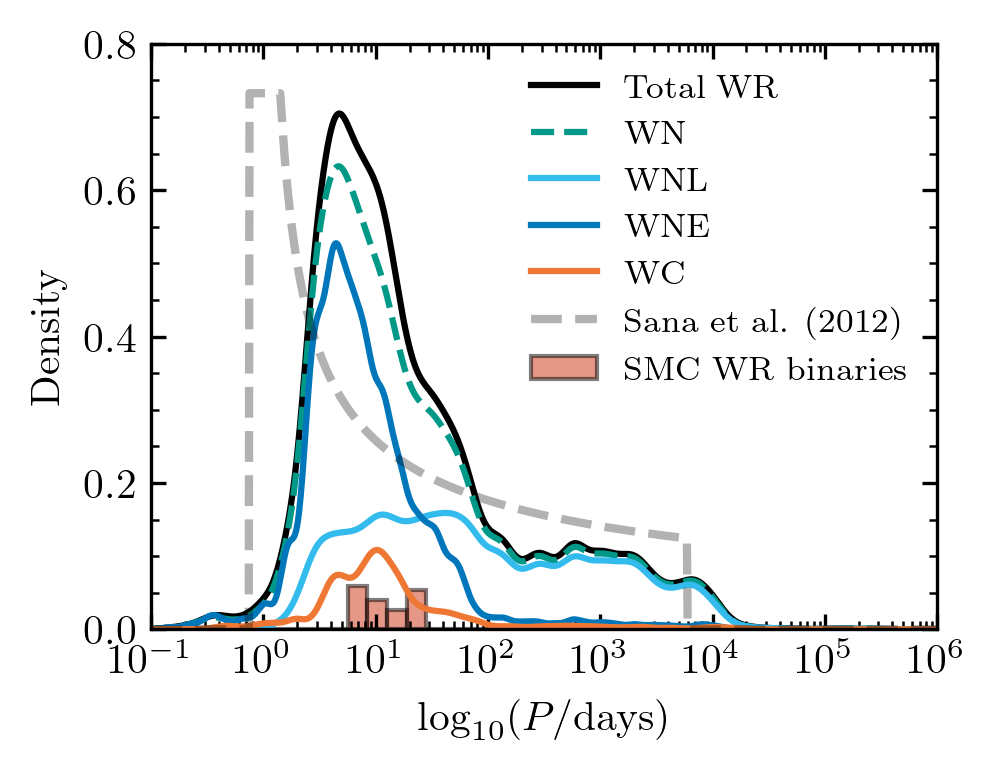

In [8]:
from scipy.stats import gaussian_kde
from posydon.popsyn.distributions import Sana12Period
period_selection = period_array[(binary_mask) & (WNL| WNE | WC)]

bw = 0.1

# all WRs in binaries
total_weight = np.sum(weight_array[(binary_mask) & (WNL| WNE | WC)])

kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WNL| WNE | WC)], bw_method=bw)
x_eval = np.linspace(-1,6, 1000)
kde_eval = kde(x_eval)
plt.plot(10**x_eval, kde_eval, color='black', label='Total WR')

# all WN in binaries
period_selection = period_array[(binary_mask) & (WNL| WNE)]
kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WNL| WNE)], bw_method=bw)
kde_eval = kde(x_eval)
fraction = np.sum(weight_array[(binary_mask) & (WNL| WNE)]) / np.sum(weight_array[(binary_mask) & (WNL| WNE | WC)])
plt.plot(10**x_eval, kde_eval*fraction, color=tol_vibrant[2], label='WN', ls='--')

# WNL
period_selection = period_array[(binary_mask) & (WNL)]
kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WNL)], bw_method=bw)
kde_eval = kde(x_eval)
fraction = np.sum(weight_array[(binary_mask) & (WNL)]) / np.sum(weight_array[(binary_mask) & (WNL| WNE | WC)])
plt.plot(10**x_eval, kde_eval*fraction, color=tol_vibrant[1], label='WNL')

# WNE 
period_selection = period_array[(binary_mask) & (WNE)]
kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WNE)], bw_method=bw)
kde_eval = kde(x_eval)
fraction = np.sum(weight_array[(binary_mask) & (WNE)]) / np.sum(weight_array[(binary_mask) & (WNL | WNE | WC)])
plt.plot(10**x_eval, kde_eval*fraction, color=tol_vibrant[0], label='WNE')


# all WC in binaries
period_selection = period_array[(binary_mask) & (WC)]
kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WC)], bw_method=bw)
kde_eval = kde(x_eval)
fraction = np.sum(weight_array[(binary_mask) & (WC)]) / np.sum(weight_array[(binary_mask) & (WNL| WNE | WC)])
plt.plot(10**x_eval, kde_eval*fraction, color=tol_vibrant[3], label='WC')

sana_dist = Sana12Period(p_min=0.75, p_max=6000.0)

# For massive stars (>15 Msun), evaluate the distribution
# Use a representative mass of ~20 Msun for typical WR progenitor
m_wr_progenitor = 20.0

# normalised to 1 in logspace, so this should be fine.
period_eval = 10**x_eval
sana_pdf = sana_dist.pdf(period_eval, m_wr_progenitor)
plt.plot(10**x_eval, sana_pdf, 'k--', linewidth=2, alpha=0.3, 
         label=f'Sana et al. (2012)')


# # binary
import pandas as pd
SMC_observations = pd.read_csv("SMC_WR.data", sep=",")

plt.hist(SMC_observations['binary_period[days]'][~pd.isna(SMC_observations['binary_period[days]'])].astype(float), bins=np.logspace(-1, 6, 41), density=True, alpha=0.5, label='SMC WR binaries', color=tol_vibrant[4], edgecolor='black')

plt.xscale('log')
plt.xlabel('$\log_{10}(P/\mathrm{days})$')
plt.ylabel('Density')
plt.legend()
plt.xlim(1e-1, 1e6)
plt.ylim(0, 0.8)
figure_paths = '/Users/max/Documents/projects/WR_population/analysis/figures/'

plt.savefig(figure_paths + 'pdf/SMC_WR_period_distributions.pdf', bbox_inches='tight')
plt.savefig(figure_paths + 'png/SMC_WR_period_distributions.png', bbox_inches='tight', dpi=300)
plt.show()

In [1]:
from posydon.utils.common_functions import convert_metallicity_to_string, orbital_separation_from_period
import matplotlib.pyplot as plt
import numpy as np

from cmap import Colormap
import pickle
from pathlib import Path
from tqdm import tqdm

# custom helper scripts
from helper_functions import calc_Teff, classify_WR_type

In [2]:
data_folder = Path('/Users/max/Documents/projects/WR_population/data/optical_depth/')
metallicity = 0.2
met_str = convert_metallicity_to_string(metallicity)
file_path = data_folder / f'WR_phases_Z{met_str}_Zsun.pkl'
with open(file_path, 'rb') as f:
    data = pickle.load(f)
    
S1_WR_data = data['S1_WR_data']
S2_WR_data = data['S2_WR_data']


In [3]:
# hydrogen-poor/free stars

WR_types = []
time_array = []
weight_array = []
state_array = []
key_array = []
star_array = []  # Track whether entry is from S1 or S2
period_array = []
separation_array = []
Teff_array = []
L_array = []
optical_depth_array = []
surface_H_array = []
surface_He_array = []
mass_array = []
mass_companion_array = []
radius_array = []
Mdot_array = []
companion_array = []

for key in tqdm(S1_WR_data):
    data = S1_WR_data[key]['data']
    weights = S1_WR_data[key]['weights']
    optical_depth = S1_WR_data[key]['optical_depth']
    
    surface_H = data['S1_surface_h1']
    surface_He = data['S1_surface_he4']
    Teff = 10**calc_Teff(data['S1_log_L'], data['S1_log_R'])
    
    # WR classification
    WN_mask,WC_mask, tmp_WR_types =  classify_WR_type(surface_H, surface_He, optical_depth)
    
    WR_types.extend(tmp_WR_types)
    time_array.extend(data['time'].values)
    weight_array.extend(weights)
    state_array.extend(data['state'].values)
    key_array.extend([key] * len(data))
    star_array.extend(['S1'] * len(data))  # Mark as S1
    Teff_array.extend(Teff)
    L_array.extend(10**data['S1_log_L'].values)
    optical_depth_array.extend(optical_depth)
    surface_H_array.extend(surface_H.values)
    surface_He_array.extend(surface_He.values)
    mass_array.extend(data['S1_mass'].values)
    mass_companion_array.extend(data['S2_mass'].values)
    radius_array.extend(10**data['S1_log_R'].values)
    Mdot_array.extend(10**data['S1_lg_mdot'].values)
    companion_array.extend(data['S2_state'].values)
    
    period_array.extend(data['orbital_period'].values)
    sep = orbital_separation_from_period(data['orbital_period'].values,
                                        data['S1_mass'].values,
                                         data['S2_mass'].values)
    
    separation_array.extend(sep)
    
    
for key in tqdm(S2_WR_data):
    data = S2_WR_data[key]['data']
    weights = S2_WR_data[key]['weights']
    optical_depth = S2_WR_data[key]['optical_depth']
    
    surface_H = data['S2_surface_h1']
    surface_He = data['S2_surface_he4']
    Teff = 10**calc_Teff(data['S2_log_L'], data['S2_log_R'])
    
    # WR classification
    WN_mask,WC_mask, tmp_WR_types =  classify_WR_type(surface_H, surface_He, optical_depth)
    
    WR_types.extend(tmp_WR_types)

    time_array.extend(data['time'].values)
    weight_array.extend(weights)
    state_array.extend(data['state'].values)
    key_array.extend([key] * len(data))
    star_array.extend(['S2'] * len(data))  # Mark as S2
    Teff_array.extend(Teff)
    L_array.extend(10**data['S2_log_L'].values)
    optical_depth_array.extend(optical_depth)
    surface_H_array.extend(surface_H.values)
    surface_He_array.extend(surface_He.values)
    mass_array.extend(data['S2_mass'].values)
    mass_companion_array.extend(data['S1_mass'].values)
    radius_array.extend(10**data['S2_log_R'].values)
    Mdot_array.extend(10**data['S2_lg_mdot'].values)
    companion_array.extend(data['S1_state'])
    period_array.extend(data['orbital_period'].values)
    sep = orbital_separation_from_period(data['orbital_period'].values,
                                        data['S2_mass'].values,
                                         data['S1_mass'].values)
    
    separation_array.extend(sep)
    

WR_types = np.array(WR_types)
time_array = np.array(time_array)
weight_array = np.array(weight_array)
state_array = np.array(state_array)
key_array = np.array(key_array)
star_array = np.array(star_array)  # Convert to array
period_array = np.array(period_array)
separation_array = np.array(separation_array)
Teff_array = np.array(Teff_array)
L_array = np.array(L_array)
optical_depth_array = np.array(optical_depth_array)
surface_H_array = np.array(surface_H_array)
surface_He_array = np.array(surface_He_array)
mass_array = np.array(mass_array)
radius_array = np.array(radius_array)
Mdot_array = np.array(Mdot_array)
companion_array = np.array(companion_array)
mass_companion_array = np.array(mass_companion_array)

100%|██████████| 31411/31411 [00:23<00:00, 1326.53it/s]


In [4]:
WN_mask = WR_types == 'WN'
WC_mask = WR_types == 'WC'
stripped_He_mask = WR_types == 'stripped-He'

In [5]:
np.unique(state_array)

array(['ERR', 'RLO1', 'RLO2', 'contact', 'detached', 'disrupted',
       'initial_RLOF', 'merged'], dtype='<U12')

In [6]:
binary_mask = (state_array == 'detached') | (state_array == 'RLO1') | (state_array == 'contact') | (state_array == 'RLO2')
single_star_mask = (state_array == 'disrupted') | (state_array == 'merged')
WR_binary_fraction = np.sum(weight_array[binary_mask & (WN_mask | WC_mask)]) / np.sum(weight_array[(binary_mask | single_star_mask) & (WN_mask | WC_mask)])
print(f"Binary fraction among WR stars: {WR_binary_fraction:.2f}")

Binary fraction among WR stars: 0.86


In [24]:
import pandas as pd
SMC_observations = pd.read_csv("SMC_WR.data", sep=",")

In [25]:
SMC_observations

,name,log_L,T_eff[kK],binary_type,WR_type,X_H,source,binary_period[days],M_WR,M_star
0,1,6.07,79,single,WN,0.50,Hainich et al. (2015),NaN,NaN,NaN
1,2,5.57,47,single,WN,0.55,Hainich et al. (2015),NaN,NaN,NaN
2,3,5.93,78,binary,WN+09,0.25,Foellmi et al. (2003) (period from Moffat+1988),10.0,20.0,20.0
3,4,5.78,45,single,WN,0.25,Schootemeijer et al. (2018) (from Hainich et ...,NaN,NaN,NaN
4,5A,6.35,45,binary,WN,0.25,Schootemeijer et al. (2018) (Koeningsberger e...,19.3,61.0,66.0
5,5B,6.25,45,binary,WN,0.25,Schootemeijer et al. (2018) (Koeningsberger e...,19.3,66.0,61.0
6,6,6.28,80,binary,WN4+O6.5I,0.40,Foellmi et al. (2003),6.5,9.0,41.0
7,7,6.10,105,binary,WN4+O6I,0.15,Foellmi et al. (2003),19.6,23.0,44.0
8,8,6.15,141,binary,WO4+O4V,0.00,Foellmi et al. (2003),16.6,19.0,61.0
9,9,6.05,100,single,WN,0.35,Hainich et al. (2015),NaN,NaN,NaN


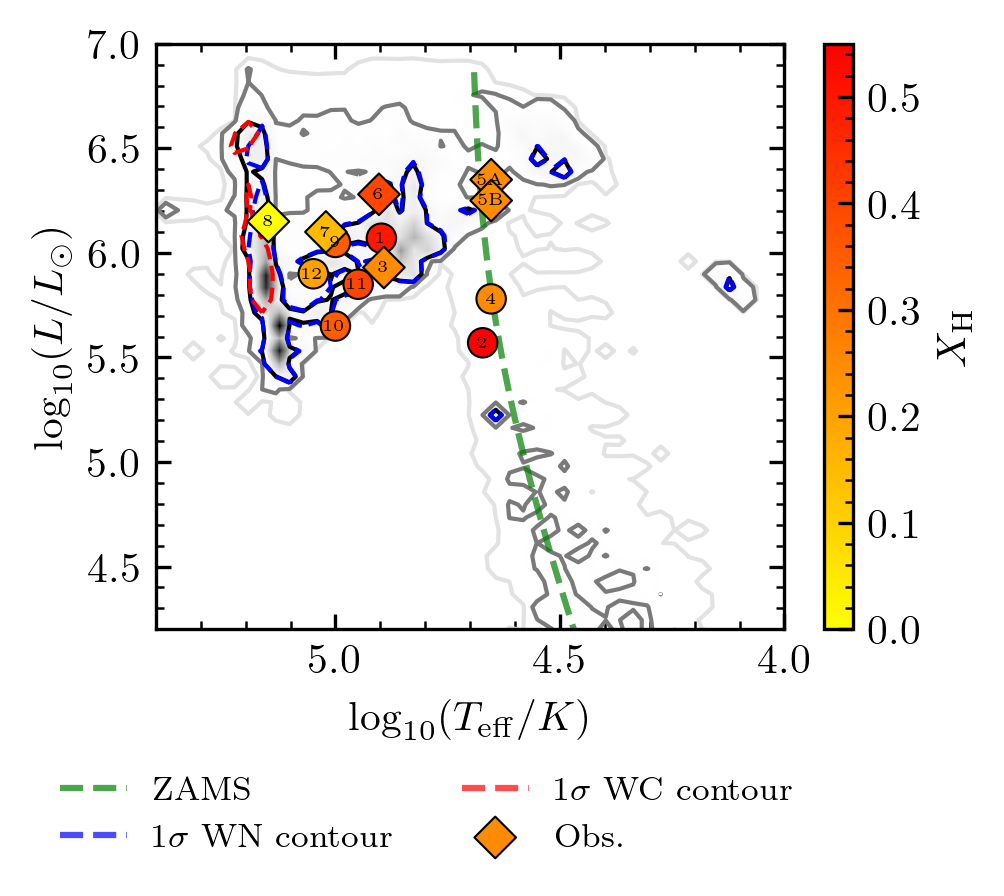

In [9]:
from helper_functions import tout_L_ZAMS, tout_R_ZAMS
# 2d histogram of Teff and L

plt.figure(figsize=(3.38, 2.535))

cm_grays = Colormap('colorbrewer:Greys')

T_bins = np.linspace(4.0, 5.5, 51)
L_bins = np.linspace(4.0, 7.0, 51)

(H0, xedges, yedges) = \
        np.histogram2d(np.log10(Teff_array)[WN_mask | WC_mask],
                       np.log10(L_array)[WN_mask | WC_mask],
                       weights=weight_array[WN_mask | WC_mask],
                       bins=[T_bins, L_bins])


H0 /= (np.diff(T_bins)[:, None] * np.diff(L_bins))
H0_sorted = np.sort(H0.flatten())[::-1]
H0_cumsum = H0_sorted.cumsum()
H0_total = H0_cumsum[-1]
# Find contour levels for 1, 2, 3 sigma (containing 68.3%, 95.4%, 99.7% of the total)
level0_1 = H0_sorted[np.searchsorted(H0_cumsum, 0.683 * H0_total)]
level0_2 = H0_sorted[np.searchsorted(H0_cumsum, 0.954 * H0_total)]
level0_3 = H0_sorted[np.searchsorted(H0_cumsum, 0.997 * H0_total)]
levels0 = [level0_3, level0_2, level0_1]

plt.imshow(H0.T,
            origin='lower',
            extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
            cmap=cm_grays.to_mpl(),
            aspect='auto',
            interpolation='bilinear')

plt.contour(H0.T,
            levels=levels0,
            colors=cm_grays([0.2, 0.6, 1.0]),
            linewidths=[1.0, 1.0, 1.0],
            extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]])


# plot WN and WC contours
H_WN, _, _ = \
        np.histogram2d(np.log10(Teff_array)[WN_mask],
                       np.log10(L_array)[WN_mask],
                       weights=weight_array[WN_mask],
                       bins=[T_bins, L_bins])
H_WN /= (np.diff(T_bins)[:, None] * np.diff(L_bins))
H_WN_sorted = np.sort(H_WN.flatten())[::-1]
H_WN_cumsum = H_WN_sorted.cumsum()
H_WN_total = H_WN_cumsum[-1]
# Find contour levels for 1, 2, 3 sigma (containing 68.3%, 95.4%, 99.7% of the total)
level_WN_3 = H_WN_sorted[np.searchsorted(H_WN_cumsum, 0.683 * H_WN_total)]
levels_WN = [level_WN_3]

plt.contour(H_WN.T,
            levels=levels_WN,
            colors='blue',
            linewidths=[1.0],
            extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
            linestyles='dashed',)

H_WC, _, _ = \
        np.histogram2d(np.log10(Teff_array)[WC_mask],
                       np.log10(L_array)[WC_mask],
                       weights=weight_array[WC_mask],
                       bins=[T_bins, L_bins])
H_WC /= (np.diff(T_bins)[:, None] * np.diff(L_bins))
H_WC_sorted = np.sort(H_WC.flatten())[::-1]
H_WC_cumsum = H_WC_sorted.cumsum()
H_WC_total = H_WC_cumsum[-1]
# Find contour levels for 1, 2, 3 sigma (containing 68.3%, 95.4%, 99.7% of the total)

level_WC_3 = H_WC_sorted[np.searchsorted(H_WC_cumsum, 0.683 * H_WC_total)]
levels_WC = [level_WC_3]
plt.contour(H_WC.T,
            levels=levels_WC,
            colors='red',
            linewidths=[1.0],
            extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
            linestyles='dashed',)


# Add ZAMS and HeMS lines
# ZAMS from Hurley et al. (2000, MNRAS, 315, 543)
# Using their fitting formulas for solar metallicity
# For M in range ~1-120 Msun, compute ZAMS L and Teff
M_zams = np.logspace(0.7, 2.5, 100) 

L_zams = tout_L_ZAMS(M_zams)
R_zams = tout_R_ZAMS(M_zams)

# Hurley et al. (2000) for ZAMS Teff (derived from their radius formula)
# log(Teff) approximation for MS stars
log_Teff_zams = calc_Teff(np.log10(L_zams), np.log10(R_zams))
log_L_zams = np.log10(L_zams)

plt.plot(log_Teff_zams, log_L_zams, 'g--', linewidth=1.5, label='ZAMS', alpha=0.7)
plt.plot([], [], 'b--', linewidth=1.5, label='$1\sigma$ WN contour', alpha=0.7)
plt.plot([], [], 'r--', linewidth=1.5, label='$1\sigma$ WC contour', alpha=0.7)
plt.xlim(5.4, 4.0)
plt.ylim(4.2, 7.0)
plt.xlabel('$\log_{10}(T_\mathrm{eff}/K)$')
plt.ylabel('$\log_{10}(L/L_\odot)$')

# Scatter plot colored by X_H
# single
tol_nightfall = Colormap('matlab:autumn_r')

obs_single = SMC_observations['binary_type'].str.contains('single')
scatter = plt.scatter(np.log10(SMC_observations['T_eff[kK]']*1e3)[obs_single], 
                      SMC_observations['log_L'][obs_single], 
                      c=SMC_observations['X_H'][obs_single], 
                      cmap=tol_nightfall.to_mpl(),
                      zorder=5,
                      edgecolors='black',
                      linewidths=0.5,
                      vmin=0.0,
                      vmax=0.55,
                      s=50)
scatter = plt.scatter(np.log10(SMC_observations['T_eff[kK]']*1e3)[~obs_single], 
                      SMC_observations['log_L'][~obs_single], 
                      c=SMC_observations['X_H'][~obs_single], 
                      cmap=tol_nightfall.to_mpl(),
                      label='Obs.', 
                      zorder=5,
                      marker='D',
                      edgecolors='black',
                      linewidths=0.5,
                      vmin=0.0,
                      vmax=0.55,
                      s=50)

for idx, row in SMC_observations.iterrows():
    plt.text(np.log10(row['T_eff[kK]']*1e3), 
             row['log_L'], 
             row['name'],  # or use idx, or any column from your dataframe 
             fontsize=4,
             ha='center',  # horizontal alignment
             va='center',  # vertical alignment
             zorder=10
             )
plt.colorbar(scatter, label='$X_\mathrm{H}$')

plt.legend(bbox_to_anchor=(-0.2, -0.2),loc='upper left', ncol=2)
plt.show()


In [10]:
binary_mask = (state_array == 'detached') | (state_array == 'RLO1') | (state_array == 'contact') | (state_array == 'RLO2')

in_binary_companions = companion_array[binary_mask]

WR_weights = weight_array[WN_mask | WC_mask]

print(np.unique(in_binary_companions))

# BH
bh_mask = companion_array == 'BH'
print('BH:', np.sum(weight_array[(binary_mask & bh_mask) & (WN_mask | WC_mask)]) / np.sum(weight_array[binary_mask & (WN_mask | WC_mask)]))
# NS
ns_mask = companion_array == 'NS'
print('NS:', np.sum(weight_array[(binary_mask & ns_mask) & (WN_mask | WC_mask)]) / np.sum(weight_array[binary_mask & (WN_mask | WC_mask)]))
# WD
wd_mask = companion_array == 'WD'
print('WD:', np.sum(weight_array[(binary_mask & wd_mask) & (WN_mask | WC_mask)]) / np.sum(weight_array[binary_mask & (WN_mask | WC_mask)]))
# stripped star
# 'stripped_He_Core_C_depleted', 'stripped_He_Core_He_burning',
# 'stripped_He_Core_He_depleted', 'stripped_He_non_burning'
ss_mask = np.core.defchararray.find(companion_array, 'stripped') != -1
print('stripped:', np.sum(weight_array[(binary_mask & ss_mask) & (WN_mask | WC_mask)]) / np.sum(weight_array[binary_mask & (WN_mask | WC_mask)]))

ms_mask = companion_array == 'H-rich_Core_H_burning'
print('MS:', np.sum(weight_array[(binary_mask & ms_mask) & (WN_mask | WC_mask)]) / np.sum(weight_array[binary_mask & (WN_mask | WC_mask)]))

# Hertzsprung gap
hg_mask = companion_array == 'H-rich_Shell_H_burning'
print('HG:', np.sum(weight_array[(binary_mask & hg_mask) & (WN_mask | WC_mask)]) / np.sum(weight_array[binary_mask & (WN_mask | WC_mask)]))
# giants
g_mask = (companion_array == 'H-rich_Core_He_burning') | (companion_array == 'H-rich_Shell_He_burning') | (companion_array == 'H-rich_He_depleted')
print('giants:', np.sum(weight_array[(binary_mask & g_mask) & (WN_mask | WC_mask)]) / np.sum(weight_array[binary_mask & (WN_mask | WC_mask)]))

# verification that this is very small:
final = (companion_array == 'H-rich_Core_C_depleted')
print('final:', np.sum(weight_array[(binary_mask & final) & (WN_mask | WC_mask)]) / np.sum(weight_array[binary_mask & (WN_mask | WC_mask)]))

['BH' 'H-rich_Core_C_depleted' 'H-rich_Core_H_burning'
 'H-rich_Core_He_burning' 'H-rich_Core_He_depleted'
 'H-rich_Shell_H_burning' 'H-rich_non_burning' 'NS' 'WD'
 'stripped_He_Core_C_depleted' 'stripped_He_Core_He_burning'
 'stripped_He_Core_He_depleted' 'stripped_He_non_burning']
BH: 0.21864783295439075
NS: 3.2359118875655914e-05
WD: 0.0
stripped: 0.04031355923800328
MS: 0.6975316797570634
HG: 0.00957727759223138
giants: 0.029790080788074616
final: 8.97141925374056e-05


# 1D figures


### Luminosity

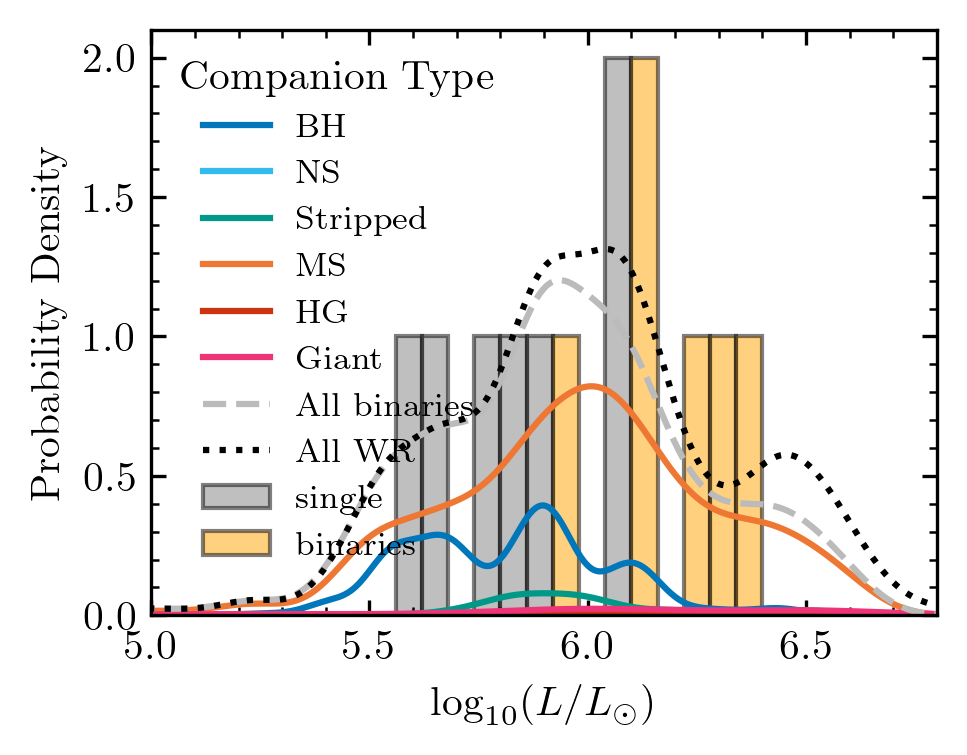

In [11]:
from scipy.stats import gaussian_kde
import cmap 

tol_vibrant = Colormap('tol:vibrant')(np.linspace(0, 1, 7))

# luminosity distribution of WR stars with different companions
L_bins = np.linspace(4.0, 7.0, 51)
L_range = np.linspace(4.0, 7.0, 1000)

plt.figure(figsize=(3.38, 2.535))
total_weight = weight_array[WN_mask | WC_mask].sum()

kde = gaussian_kde(np.log10(L_array[(WN_mask | WC_mask) & (binary_mask & bh_mask)]), weights=weight_array[(WN_mask | WC_mask) & (binary_mask & bh_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & bh_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='BH', color=tol_vibrant[0])

kde = gaussian_kde(np.log10(L_array[(WN_mask | WC_mask) & (binary_mask & ns_mask)]), weights=weight_array[(WN_mask | WC_mask) & (binary_mask & ns_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & ns_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='NS', color=tol_vibrant[1])

kde = gaussian_kde(np.log10(L_array[(WN_mask | WC_mask) & (binary_mask & ss_mask)]), weights=weight_array[(WN_mask | WC_mask) & (binary_mask & ss_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & ss_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='Stripped', color=tol_vibrant[2])

kde = gaussian_kde(np.log10(L_array[(WN_mask | WC_mask) & (binary_mask & ms_mask)]), weights=weight_array[(WN_mask | WC_mask) & (binary_mask & ms_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & ms_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='MS', color=tol_vibrant[3])

kde = gaussian_kde(np.log10(L_array[(WN_mask | WC_mask) & (binary_mask & hg_mask)]), weights=weight_array[(WN_mask | WC_mask) & (binary_mask & hg_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & hg_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='HG', color=tol_vibrant[4])

kde = gaussian_kde(np.log10(L_array[(WN_mask | WC_mask) & (binary_mask & g_mask)]), weights=weight_array[(WN_mask | WC_mask) & (binary_mask & g_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & g_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='Giant', color=tol_vibrant[5])

kde = gaussian_kde(np.log10(L_array[(WN_mask | WC_mask) & binary_mask]), weights=weight_array[(WN_mask | WC_mask) & binary_mask])
weight = weight_array[(WN_mask | WC_mask) & binary_mask].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='All binaries', color=tol_vibrant[6], linestyle='dashed')

kdw = gaussian_kde(np.log10(L_array[(WN_mask | WC_mask) & (binary_mask | single_star_mask)]), weights=weight_array[(WN_mask | WC_mask) & (binary_mask | single_star_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask | single_star_mask)].sum()/total_weight

plt.plot(L_range, kdw(L_range)*weight, label='All WR', color='black', linestyle='dotted')

plt.ylabel('Probability Density')
plt.xlabel('$\log_{10}(L/L_\odot)$')
plt.xlim(5.0, 6.8)


# single
plt.hist(SMC_observations['log_L'][obs_single], bins=L_bins, density=False, alpha=0.5, label='single', color='gray', edgecolor='black')
# binary
plt.hist(SMC_observations['log_L'][~obs_single], bins=L_bins, density=False, alpha=0.5, label='binaries', color='orange', edgecolor='black')

plt.legend(title='Companion Type')
plt.show()

### Teff

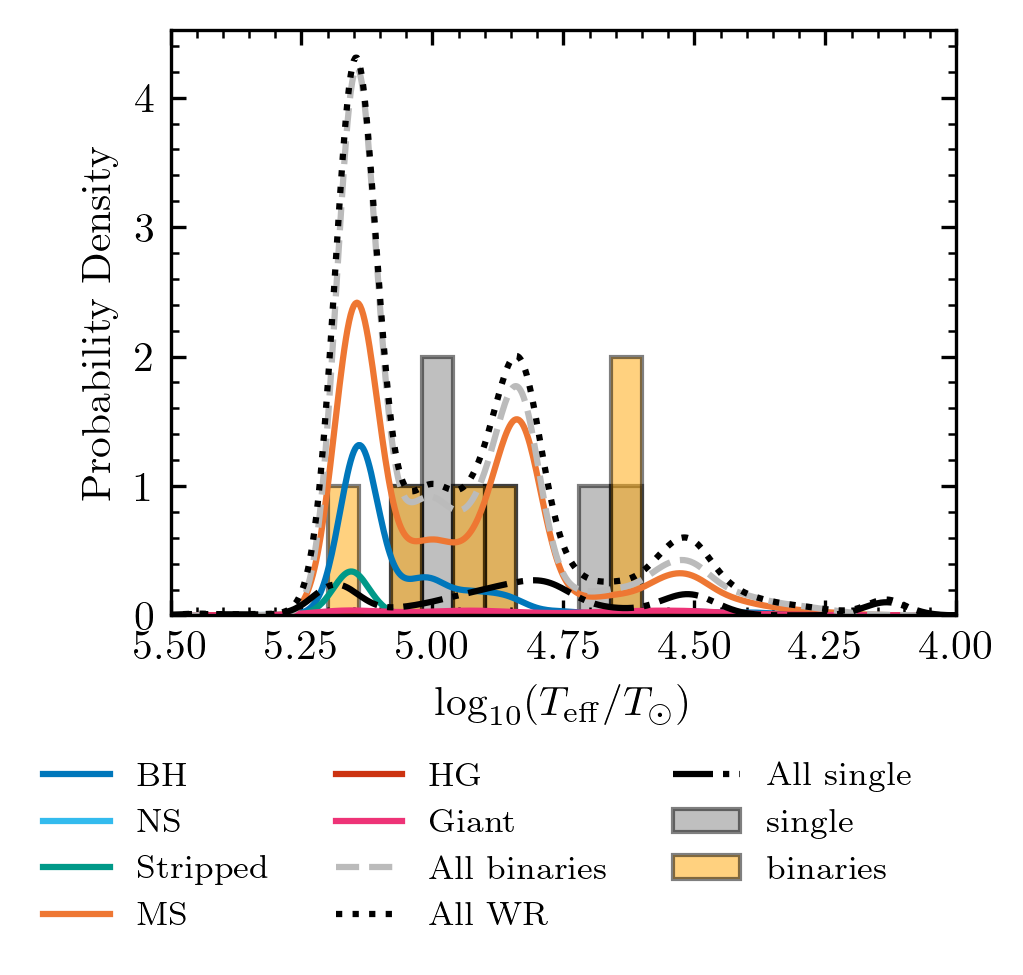

In [12]:
from scipy.stats import gaussian_kde
import cmap 

tol_vibrant = Colormap('tol:vibrant')(np.linspace(0, 1, 7))

# luminosity distribution of WR stars with different companions
L_bins = np.linspace(4.0, 7.0, 51)
L_range = np.linspace(4.0, 7.0, 1000)

plt.figure(figsize=(3.38, 2.535))
total_weight = weight_array[WN_mask | WC_mask].sum()

kde = gaussian_kde(np.log10(Teff_array[(WN_mask | WC_mask) & (binary_mask & bh_mask)]), weights=weight_array[(WN_mask | WC_mask) & (binary_mask & bh_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & bh_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='BH', color=tol_vibrant[0])

kde = gaussian_kde(np.log10(Teff_array[(WN_mask | WC_mask) & (binary_mask & ns_mask)]), weights=weight_array[(WN_mask | WC_mask) & (binary_mask & ns_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & ns_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='NS', color=tol_vibrant[1])

kde = gaussian_kde(np.log10(Teff_array[(WN_mask | WC_mask) & (binary_mask & ss_mask)]), weights=weight_array[(WN_mask | WC_mask) & (binary_mask & ss_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & ss_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='Stripped', color=tol_vibrant[2])

kde = gaussian_kde(np.log10(Teff_array[(WN_mask | WC_mask) & (binary_mask & ms_mask)]), weights=weight_array[(WN_mask | WC_mask) & (binary_mask & ms_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & ms_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='MS', color=tol_vibrant[3])

kde = gaussian_kde(np.log10(Teff_array[(WN_mask | WC_mask) & (binary_mask & hg_mask)]), weights=weight_array[(WN_mask | WC_mask) & (binary_mask & hg_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & hg_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='HG', color=tol_vibrant[4])

kde = gaussian_kde(np.log10(Teff_array[(WN_mask | WC_mask) & (binary_mask & g_mask)]), weights=weight_array[(WN_mask | WC_mask) & (binary_mask & g_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & g_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='Giant', color=tol_vibrant[5])

kde = gaussian_kde(np.log10(Teff_array[(WN_mask | WC_mask) & binary_mask]), weights=weight_array[(WN_mask | WC_mask) & binary_mask])
weight = weight_array[(WN_mask | WC_mask) & binary_mask].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='All binaries', color=tol_vibrant[6], linestyle='dashed')

kdw = gaussian_kde(np.log10(Teff_array[(WN_mask | WC_mask) & (binary_mask | single_star_mask)]), weights=weight_array[(WN_mask | WC_mask) & (binary_mask | single_star_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask | single_star_mask)].sum()/total_weight
plt.plot(L_range, kdw(L_range)*weight, label='All WR', color='black', linestyle='dotted')

kde = kdw = gaussian_kde(np.log10(Teff_array[(WN_mask | WC_mask) & (single_star_mask)]), weights=weight_array[(WN_mask | WC_mask) & (single_star_mask)])
weight = weight_array[(WN_mask | WC_mask) & (single_star_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='All single', color='black', linestyle='dashdot')


plt.ylabel('Probability Density')
plt.xlabel('$\log_{10}(T_\mathrm{eff}/T_\odot)$')
plt.xlim(5.5, 4)

# single
plt.hist(np.log10(SMC_observations['T_eff[kK]'][obs_single]*1e3), bins=L_bins, density=False, alpha=0.5, label='single', color='gray', edgecolor='black')
# binary
plt.hist(np.log10(SMC_observations['T_eff[kK]'][~obs_single]*1e3), bins=L_bins, density=False, alpha=0.5, label='binaries', color='orange', edgecolor='black')

plt.legend(bbox_to_anchor=(-0.2, -0.2),loc='upper left', ncol=3)
plt.show()

### Period distribution with companion type

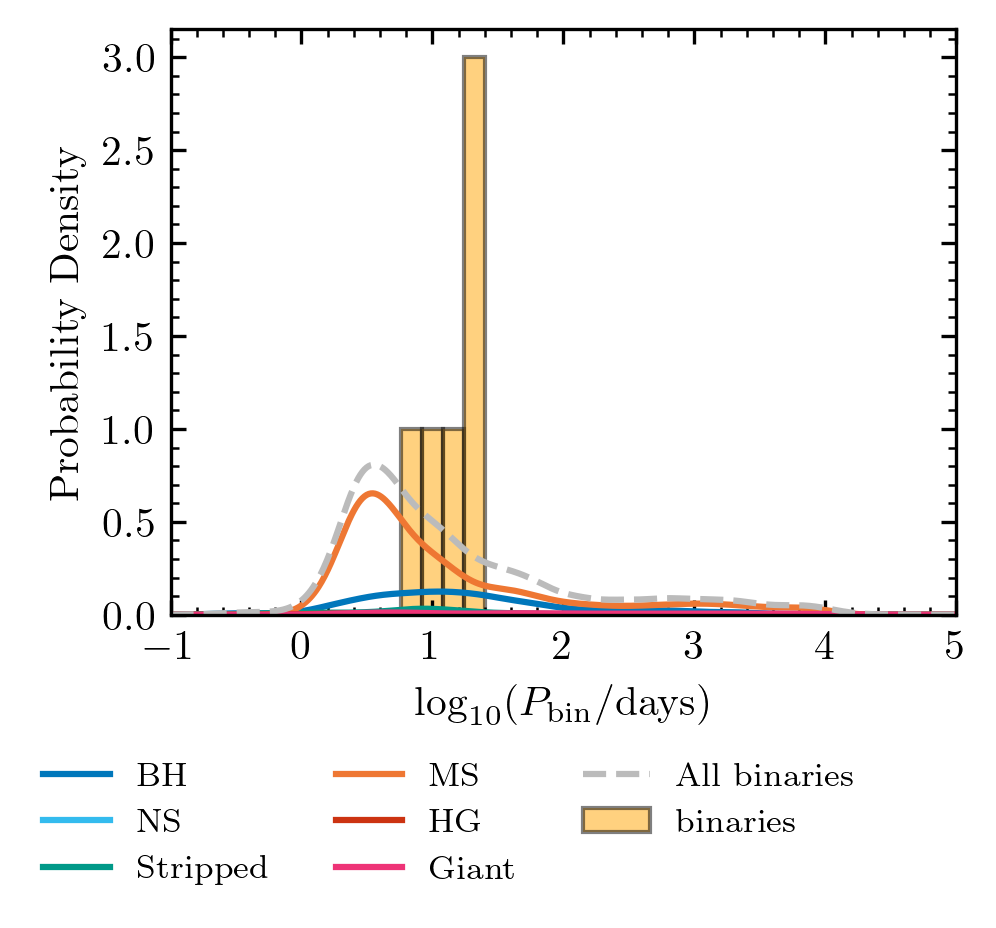

In [13]:
from scipy.stats import gaussian_kde
import cmap 

tol_vibrant = Colormap('tol:vibrant')(np.linspace(0, 1, 7))

# luminosity distribution of WR stars with different companions
L_bins = np.linspace(-1, 7.0, 51)
L_range = np.linspace(-1, 7.0, 1000)

plt.figure(figsize=(3.38, 2.535))
total_weight = weight_array[(WN_mask | WC_mask) & binary_mask].sum()

kde = gaussian_kde(np.log10(period_array[(WN_mask | WC_mask) & (binary_mask & bh_mask)]), weights=weight_array[(WN_mask | WC_mask) & (binary_mask & bh_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & bh_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='BH', color=tol_vibrant[0])

kde = gaussian_kde(np.log10(period_array[(WN_mask | WC_mask) & (binary_mask & ns_mask)]), weights=weight_array[(WN_mask | WC_mask) & (binary_mask & ns_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & ns_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='NS', color=tol_vibrant[1])

kde = gaussian_kde(np.log10(period_array[(WN_mask | WC_mask) & (binary_mask & ss_mask)]), weights=weight_array[(WN_mask | WC_mask) & (binary_mask & ss_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & ss_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='Stripped', color=tol_vibrant[2])

kde = gaussian_kde(np.log10(period_array[(WN_mask | WC_mask) & (binary_mask & ms_mask)]), weights=weight_array[(WN_mask | WC_mask) & (binary_mask & ms_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & ms_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='MS', color=tol_vibrant[3])

kde = gaussian_kde(np.log10(period_array[(WN_mask | WC_mask) & (binary_mask & hg_mask)]), weights=weight_array[(WN_mask | WC_mask) & (binary_mask & hg_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & hg_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='HG', color=tol_vibrant[4])

kde = gaussian_kde(np.log10(period_array[(WN_mask | WC_mask) & (binary_mask & g_mask)]), weights=weight_array[(WN_mask | WC_mask) & (binary_mask & g_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & g_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='Giant', color=tol_vibrant[5])

kde = gaussian_kde(np.log10(period_array[(WN_mask | WC_mask) & binary_mask]), weights=weight_array[(WN_mask | WC_mask) & binary_mask])
weight = weight_array[(WN_mask | WC_mask) & binary_mask].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='All binaries', color=tol_vibrant[6], linestyle='dashed')

plt.ylabel('Probability Density')
plt.xlabel('$\log_{10}(P_\mathrm{bin}/\mathrm{days})$')
plt.xlim(-1, 5)

# # binary
plt.hist(np.log10(SMC_observations['binary_period[days]'][~obs_single]), bins=L_bins, density=False, alpha=0.5, label='binaries', color='orange', edgecolor='black')

plt.legend(bbox_to_anchor=(-0.2, -0.2),loc='upper left', ncol=3)
plt.show()

More conservative mass transfer could lead to wider orbits?

### Mass ratio distribution

2    1.000000
6    4.555556
7    1.913043
8    3.210526
dtype: float64


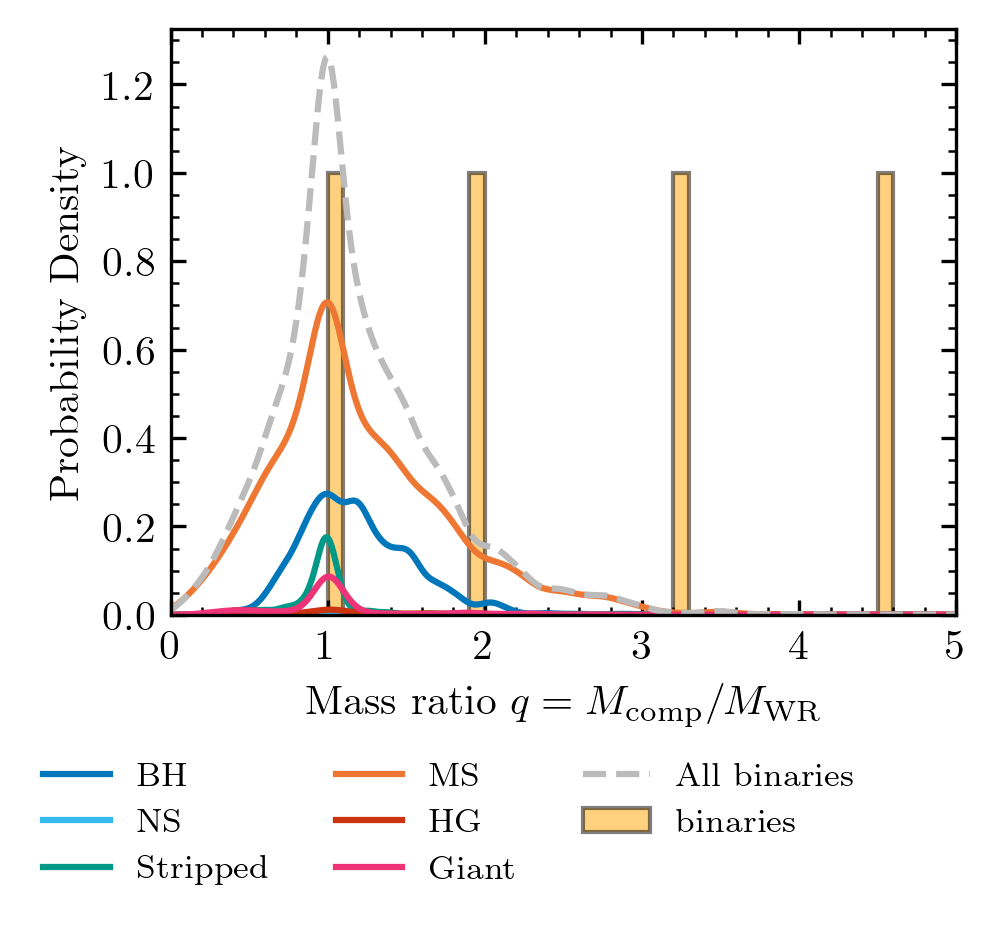

In [30]:
from scipy.stats import gaussian_kde
import cmap 

tol_vibrant = Colormap('tol:vibrant')(np.linspace(0, 1, 7))

# luminosity distribution of WR stars with different companions
L_bins = np.linspace(0.0, 5.0, 51)
L_range = np.linspace(0.0, 5.0, 1000)

plt.figure(figsize=(3.38, 2.535))
total_weight = weight_array[(WN_mask | WC_mask) & binary_mask].sum()

kde = gaussian_kde(mass_companion_array[(WN_mask | WC_mask) & (binary_mask & bh_mask)]/mass_array[(WN_mask | WC_mask) & (binary_mask & bh_mask)], weights=weight_array[(WN_mask | WC_mask) & (binary_mask & bh_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & bh_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='BH', color=tol_vibrant[0])

kde = gaussian_kde(mass_companion_array[(WN_mask | WC_mask) & (binary_mask & ns_mask)]/mass_array[(WN_mask | WC_mask) & (binary_mask & ns_mask)], weights=weight_array[(WN_mask | WC_mask) & (binary_mask & ns_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & ns_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='NS', color=tol_vibrant[1])

kde = gaussian_kde(mass_companion_array[(WN_mask | WC_mask) & (binary_mask & ss_mask)]/mass_array[(WN_mask | WC_mask) & (binary_mask & ss_mask)], weights=weight_array[(WN_mask | WC_mask) & (binary_mask & ss_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & ss_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='Stripped', color=tol_vibrant[2])

kde = gaussian_kde(mass_companion_array[(WN_mask | WC_mask) & (binary_mask & ms_mask)]/mass_array[(WN_mask | WC_mask) & (binary_mask & ms_mask)], weights=weight_array[(WN_mask | WC_mask) & (binary_mask & ms_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & ms_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='MS', color=tol_vibrant[3])

kde = gaussian_kde(mass_companion_array[(WN_mask | WC_mask) & (binary_mask & hg_mask)]/mass_array[(WN_mask | WC_mask) & (binary_mask & hg_mask)], weights=weight_array[(WN_mask | WC_mask) & (binary_mask & hg_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & hg_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='HG', color=tol_vibrant[4])

kde = gaussian_kde(mass_companion_array[(WN_mask | WC_mask) & (binary_mask & g_mask)]/mass_array[(WN_mask | WC_mask) & (binary_mask & g_mask)], weights=weight_array[(WN_mask | WC_mask) & (binary_mask & g_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & g_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='Giant', color=tol_vibrant[5])

kde = gaussian_kde(mass_companion_array[(WN_mask | WC_mask) & binary_mask]/mass_array[(WN_mask | WC_mask) & binary_mask], weights=weight_array[(WN_mask | WC_mask) & binary_mask])
weight = weight_array[(WN_mask | WC_mask) & binary_mask].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='All binaries', color=tol_vibrant[6], linestyle='dashed')

plt.ylabel('Probability Density')
plt.xlabel('Mass ratio $q = M_\mathrm{comp}/M_\mathrm{WR}$')
plt.xlim(0, 5)

# # binary
exclude_5 = SMC_observations['name'].str.contains('5')
plt.hist(SMC_observations['M_star'][~obs_single & ~exclude_5]/SMC_observations['M_WR'][~obs_single & ~exclude_5], bins=L_bins, density=False, alpha=0.5, label='binaries', color='orange', edgecolor='black')
print(SMC_observations['M_star'][~obs_single & ~exclude_5]/SMC_observations['M_WR'][~obs_single & ~exclude_5])

plt.legend(bbox_to_anchor=(-0.2, -0.2),loc='upper left', ncol=3)
plt.show()

2    1.000000
6    0.219512
7    0.522727
8    0.311475
dtype: float64


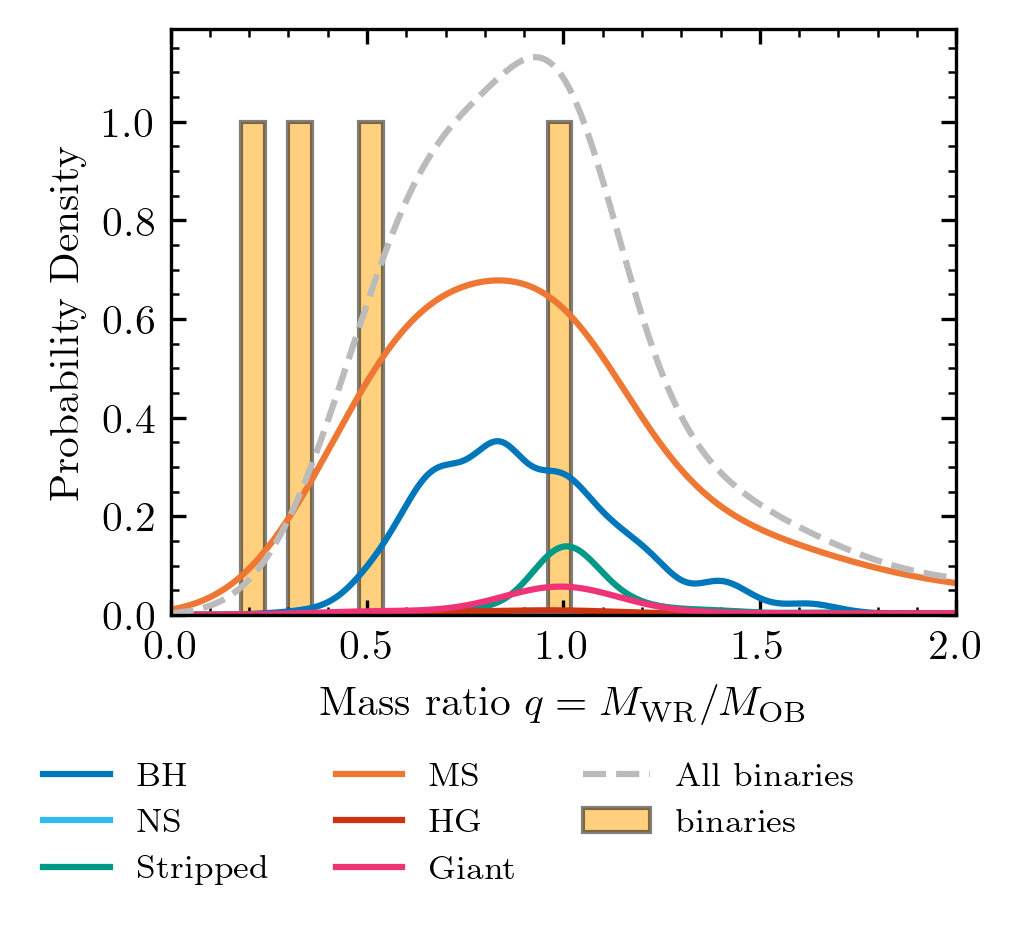

In [32]:
from scipy.stats import gaussian_kde
import cmap 

tol_vibrant = Colormap('tol:vibrant')(np.linspace(0, 1, 7))

# luminosity distribution of WR stars with different companions
L_bins = np.linspace(0.0, 3.0, 51)
L_range = np.linspace(0.0, 3.0, 1000)

plt.figure(figsize=(3.38, 2.535))
total_weight = weight_array[(WN_mask | WC_mask) & binary_mask].sum()

kde = gaussian_kde(mass_array[(WN_mask | WC_mask) & (binary_mask & bh_mask)]/mass_companion_array[(WN_mask | WC_mask) & (binary_mask & bh_mask)], weights=weight_array[(WN_mask | WC_mask) & (binary_mask & bh_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & bh_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='BH', color=tol_vibrant[0])

kde = gaussian_kde(mass_array[(WN_mask | WC_mask) & (binary_mask & ns_mask)]/mass_companion_array[(WN_mask | WC_mask) & (binary_mask & ns_mask)], weights=weight_array[(WN_mask | WC_mask) & (binary_mask & ns_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & ns_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='NS', color=tol_vibrant[1])

kde = gaussian_kde(mass_array[(WN_mask | WC_mask) & (binary_mask & ss_mask)]/mass_companion_array[(WN_mask | WC_mask) & (binary_mask & ss_mask)], weights=weight_array[(WN_mask | WC_mask) & (binary_mask & ss_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & ss_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='Stripped', color=tol_vibrant[2])

kde = gaussian_kde(mass_array[(WN_mask | WC_mask) & (binary_mask & ms_mask)]/mass_companion_array[(WN_mask | WC_mask) & (binary_mask & ms_mask)], weights=weight_array[(WN_mask | WC_mask) & (binary_mask & ms_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & ms_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='MS', color=tol_vibrant[3])

kde = gaussian_kde(mass_array[(WN_mask | WC_mask) & (binary_mask & hg_mask)]/mass_companion_array[(WN_mask | WC_mask) & (binary_mask & hg_mask)], weights=weight_array[(WN_mask | WC_mask) & (binary_mask & hg_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & hg_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='HG', color=tol_vibrant[4])

kde = gaussian_kde(mass_array[(WN_mask | WC_mask) & (binary_mask & g_mask)]/mass_companion_array[(WN_mask | WC_mask) & (binary_mask & g_mask)], weights=weight_array[(WN_mask | WC_mask) & (binary_mask & g_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & g_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='Giant', color=tol_vibrant[5])

kde = gaussian_kde(mass_array[(WN_mask | WC_mask) & binary_mask]/mass_companion_array[(WN_mask | WC_mask) & binary_mask], weights=weight_array[(WN_mask | WC_mask) & binary_mask])
weight = weight_array[(WN_mask | WC_mask) & binary_mask].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='All binaries', color=tol_vibrant[6], linestyle='dashed')

plt.ylabel('Probability Density')
plt.xlabel('Mass ratio $q = M_\mathrm{WR}/M_\mathrm{OB}$')
plt.xlim(0, 2)

# # binary
exclude_5 = SMC_observations['name'].str.contains('5')
plt.hist(SMC_observations['M_WR'][~obs_single & ~exclude_5]/SMC_observations['M_star'][~obs_single & ~exclude_5], bins=L_bins, density=False, alpha=0.5, label='binaries', color='orange', edgecolor='black')
print(SMC_observations['M_WR'][~obs_single & ~exclude_5]/SMC_observations['M_star'][~obs_single & ~exclude_5])

plt.legend(bbox_to_anchor=(-0.2, -0.2),loc='upper left', ncol=3)
plt.show()

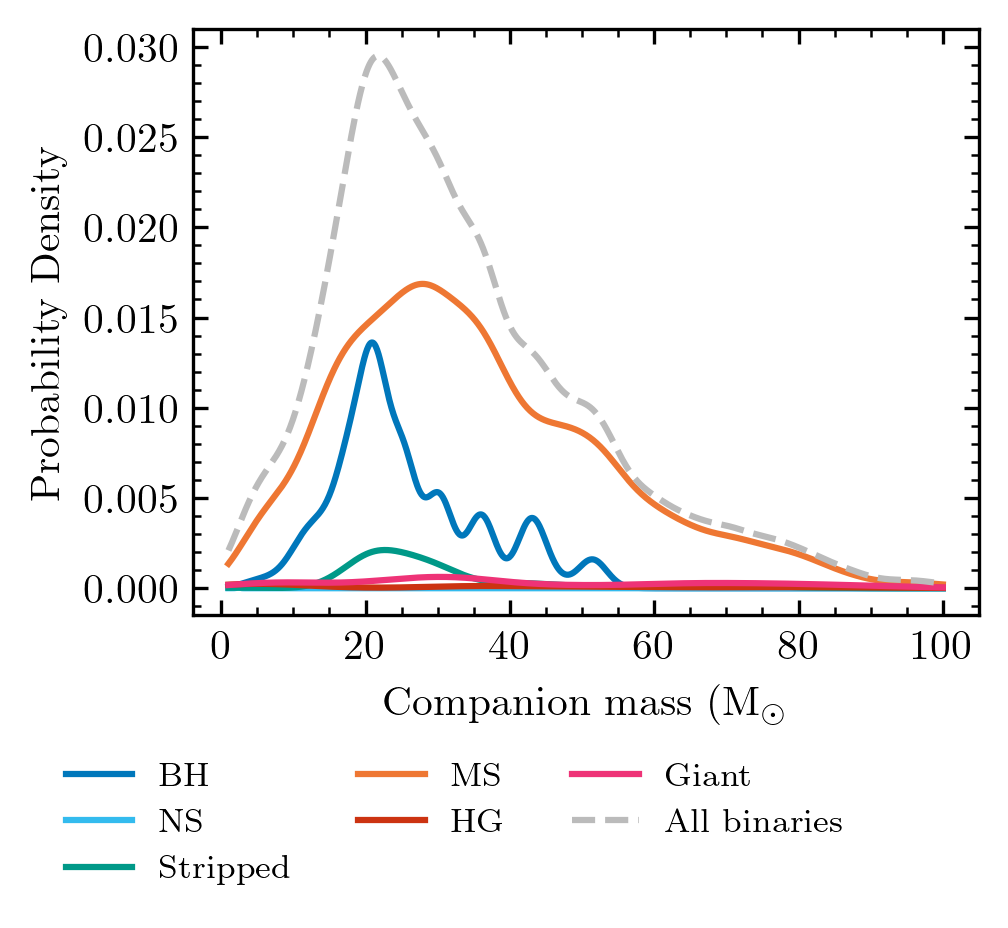

In [16]:
from scipy.stats import gaussian_kde
import cmap 

tol_vibrant = Colormap('tol:vibrant')(np.linspace(0, 1, 7))

# luminosity distribution of WR stars with different companions
L_bins = np.linspace(1, 100, 51)
L_range = np.linspace(1.0, 100, 1000)

plt.figure(figsize=(3.38, 2.535))
total_weight = weight_array[(WN_mask | WC_mask) & binary_mask].sum()

kde = gaussian_kde(mass_companion_array[(WN_mask | WC_mask) & (binary_mask & bh_mask)], weights=weight_array[(WN_mask | WC_mask) & (binary_mask & bh_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & bh_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='BH', color=tol_vibrant[0])

kde = gaussian_kde(mass_companion_array[(WN_mask | WC_mask) & (binary_mask & ns_mask)], weights=weight_array[(WN_mask | WC_mask) & (binary_mask & ns_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & ns_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='NS', color=tol_vibrant[1])

kde = gaussian_kde(mass_companion_array[(WN_mask | WC_mask) & (binary_mask & ss_mask)], weights=weight_array[(WN_mask | WC_mask) & (binary_mask & ss_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & ss_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='Stripped', color=tol_vibrant[2])

kde = gaussian_kde(mass_companion_array[(WN_mask | WC_mask) & (binary_mask & ms_mask)], weights=weight_array[(WN_mask | WC_mask) & (binary_mask & ms_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & ms_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='MS', color=tol_vibrant[3])

kde = gaussian_kde(mass_companion_array[(WN_mask | WC_mask) & (binary_mask & hg_mask)], weights=weight_array[(WN_mask | WC_mask) & (binary_mask & hg_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & hg_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='HG', color=tol_vibrant[4])

kde = gaussian_kde(mass_companion_array[(WN_mask | WC_mask) & (binary_mask & g_mask)], weights=weight_array[(WN_mask | WC_mask) & (binary_mask & g_mask)])
weight = weight_array[(WN_mask | WC_mask) & (binary_mask & g_mask)].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='Giant', color=tol_vibrant[5])

kde = gaussian_kde(mass_companion_array[(WN_mask | WC_mask) & binary_mask], weights=weight_array[(WN_mask | WC_mask) & binary_mask])
weight = weight_array[(WN_mask | WC_mask) & binary_mask].sum()/total_weight
plt.plot(L_range, kde(L_range)*weight, label='All binaries', color=tol_vibrant[6], linestyle='dashed')

plt.ylabel('Probability Density')
plt.xlabel('Companion mass (M$_\odot$')


# # binary
#plt.hist(np.log10(SMC_observations['binary_period[days]'][~obs_single]), bins=L_bins, density=False, alpha=0.5, label='binaries', color='orange', edgecolor='black')

plt.legend(bbox_to_anchor=(-0.2, -0.2),loc='upper left', ncol=3)
plt.show()

# 2D figures

### mass ratio vs period

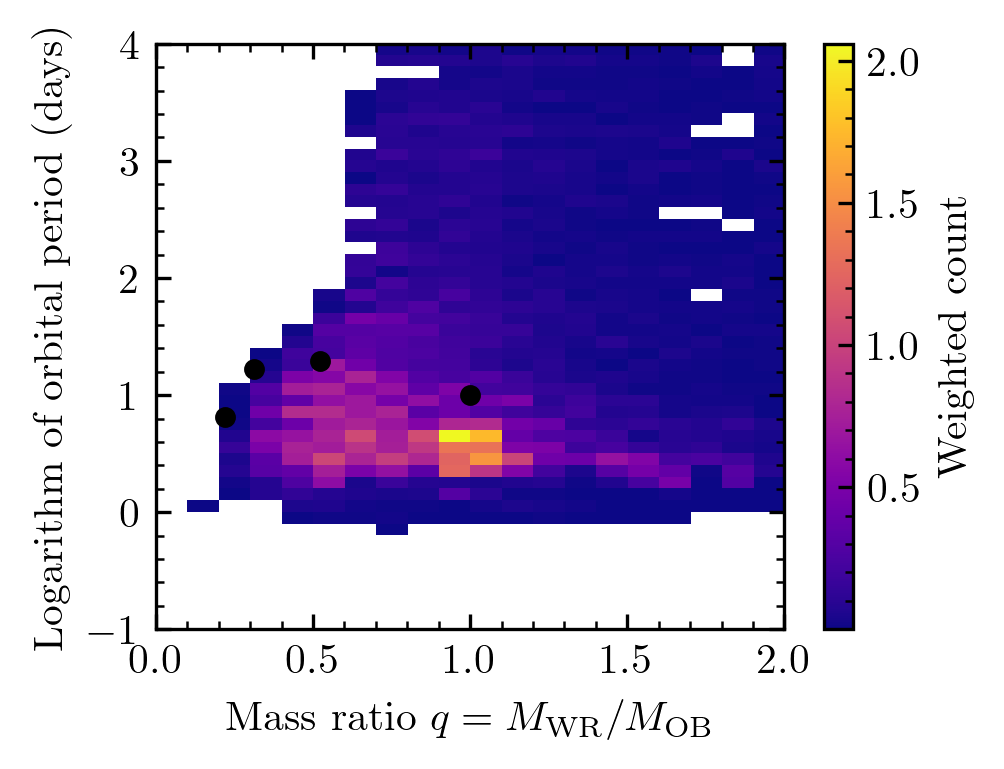

In [43]:
mass_ratio = np.linspace(0,5,51)
log_P = np.linspace(-1,4,51)

h, x_edges, y_edges = np.histogram2d(mass_array[(WN_mask | WC_mask) & (binary_mask & ms_mask)]/mass_companion_array[(WN_mask | WC_mask) & (binary_mask & ms_mask)],
                                     np.log10(period_array[(WN_mask | WC_mask) & (binary_mask & ms_mask)]),
                                     weights=weight_array[(WN_mask | WC_mask) & (binary_mask & ms_mask)],
                                     bins=[mass_ratio, log_P], density=True)

h = np.where(h==0, np.nan, h)  # Replace zeros with NaN for better visualization

plt.figure(figsize=(3.38, 2.535))
plt.imshow(h.T, origin='lower', aspect='auto', extent=[x_edges[0], x_edges[-1], y_edges[0], y_edges[-1]], cmap='plasma')
plt.colorbar(label='Weighted count')
plt.xlabel('Mass ratio $q = M_\mathrm{WR}/M_\mathrm{OB}$')
plt.ylabel('Logarithm of orbital period (days)')

plt.scatter((SMC_observations['M_WR']/SMC_observations['M_star'])[~obs_single & ~exclude_5],
            np.log10(SMC_observations['binary_period[days]'][~obs_single & ~exclude_5]),
            color='black')

plt.xlim(0,2)
plt.show()


In [18]:
from posydon.popsyn.synthetic_population import Population
import pandas as pd
population_run_folder = Path('/Users/max/Documents/projects/WR_population/population_synthesis/runs/2025_11_04/')
population_file = population_run_folder / f"{met_str}_Zsun_population.h5"

pop = Population(str(population_file))

Missing ini parameter: metallicity


In [37]:
HMS_HMS_interaction = pop.oneline['interp_class_HMS_HMS']
CO_HMS_RLO_interaction = pop.oneline['interp_class_CO_HMS_RLO']

In [38]:
S1_stable_indices = set(np.where(HMS_HMS_interaction == 'stable_MT')[0])
S1_unstable_indices = set(np.where(HMS_HMS_interaction == 'unstable_MT')[0])
S1_reverse_stable_indices = set(np.where(HMS_HMS_interaction == 'reverse_stable_MT')[0])
S1_no_MT_indices = set(np.where((HMS_HMS_interaction == 'no_MT') | pd.isna(HMS_HMS_interaction))[0])

In [39]:
WR_mask =( WR_types == 'WN' )| (WR_types == 'WC')

# S1 interaction masks - only apply to S1 entries
S1_entries = (star_array == 'S1')
mask_stable = S1_entries & np.isin(key_array, np.array(list(S1_stable_indices)))
mask_unstable = S1_entries & np.isin(key_array, np.array(list(S1_unstable_indices)))
mask_reverse_stable = S1_entries & np.isin(key_array, np.array(list(S1_reverse_stable_indices)))
mask_no_MT = S1_entries & np.isin(key_array, np.array(list(S1_no_MT_indices)))


S2_stable_indices = set(np.where(CO_HMS_RLO_interaction == 'stable_MT')[0])
S2_unstable_indices = set(np.where(CO_HMS_RLO_interaction == 'unstable_MT')[0])
S2_reverse_stable_indices = set(np.where(CO_HMS_RLO_interaction == 'reverse_stable_MT')[0])
S2_no_MT_indices = set(np.where((CO_HMS_RLO_interaction == 'no_MT') | pd.isna(CO_HMS_RLO_interaction))[0])

# S2 interaction masks - only apply to S2 entries
S2_entries = (star_array == 'S2')
S2_mask_stable = S2_entries & np.isin(key_array, np.array(list(S2_stable_indices)))
S2_mask_unstable = S2_entries & np.isin(key_array, np.array(list(S2_unstable_indices)))
S2_mask_reverse_stable = S2_entries & np.isin(key_array, np.array(list(S2_reverse_stable_indices)))
S2_mask_no_MT = S2_entries & np.isin(key_array, np.array(list(S2_no_MT_indices)))

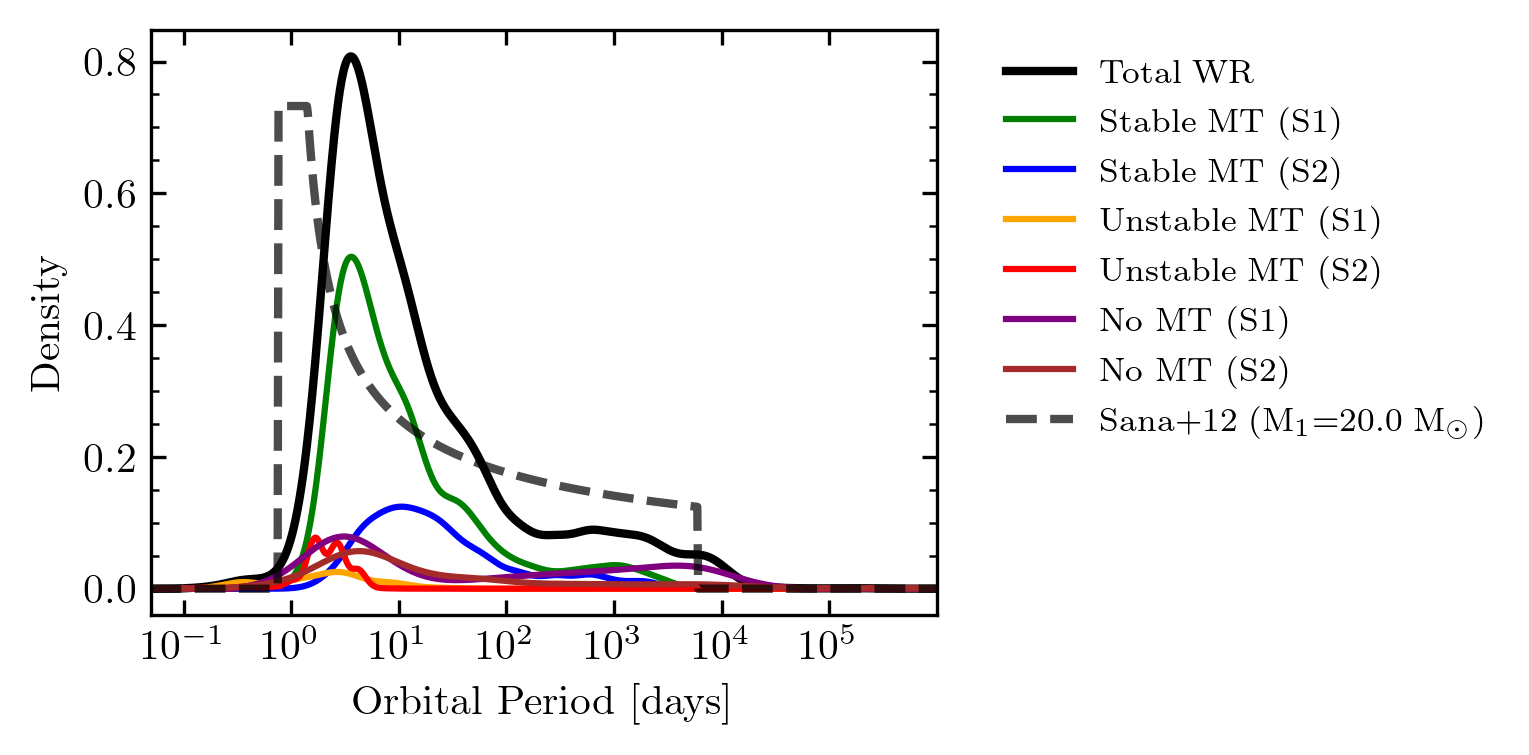

In [41]:
# Import Sana+12 period distribution
from posydon.popsyn.distributions import Sana12Period
from scipy.stats import gaussian_kde

# Define common x_eval range for ALL KDEs
period_selection_all = period_array[(binary_mask) & (WR_mask)]
x_eval = np.linspace(np.log10(np.min(period_selection_all)), np.log10(np.max(period_selection_all)), 1000)

# Total WR distribution (for reference)
period_selection = period_array[(binary_mask) & (WN_mask | WC_mask)]
kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WN_mask | WC_mask)])
kde_eval = kde(x_eval)
plt.plot(10**x_eval, kde_eval, color='black', label='Total WR', linewidth=2)

# Initialize sum
h = np.zeros_like(x_eval)

# S1 stable MT
period_selection = period_array[(binary_mask) & (WR_mask) & (mask_stable)]
if len(period_selection) > 0:
    kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WR_mask) & (mask_stable)])
    kde_eval = kde(x_eval)
    fraction = np.sum(weight_array[(binary_mask) & (WR_mask) & (mask_stable)]) / np.sum(weight_array[(binary_mask) & (WR_mask)])
    h += kde_eval * fraction
    plt.plot(10**x_eval, kde_eval*fraction, color='green', label='Stable MT (S1)')

# S2 stable MT
period_selection = period_array[(binary_mask) & (WR_mask) & (S2_mask_stable)]
if len(period_selection) > 0:
    kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WR_mask) & (S2_mask_stable)])
    kde_eval = kde(x_eval)
    fraction = np.sum(weight_array[(binary_mask) & (WR_mask) & (S2_mask_stable)]) / np.sum(weight_array[(binary_mask) & (WR_mask)])
    h += kde_eval * fraction
    plt.plot(10**x_eval, kde_eval*fraction, color='blue', label='Stable MT (S2)')

# unstable MT
period_selection = period_array[(binary_mask) & (WR_mask) & (mask_unstable)]
if len(period_selection) > 0:
    kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WR_mask) & (mask_unstable)])
    kde_eval = kde(x_eval)
    fraction = np.sum(weight_array[(binary_mask) & (WR_mask) & (mask_unstable)]) / np.sum(weight_array[(binary_mask) & (WR_mask)])
    h += kde_eval * fraction
    plt.plot(10**x_eval, kde_eval*fraction, color='orange', label='Unstable MT (S1)')

# unstable S2 MT
period_selection = period_array[(binary_mask) & (WR_mask) & (S2_mask_unstable)]
if len(period_selection) > 0:
    kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WR_mask) & (S2_mask_unstable)])
    kde_eval = kde(x_eval)
    fraction = np.sum(weight_array[(binary_mask) & (WR_mask) & (S2_mask_unstable)]) / np.sum(weight_array[(binary_mask) & (WR_mask)])
    h += kde_eval * fraction
    plt.plot(10**x_eval, kde_eval*fraction, color='red', label='Unstable MT (S2)')

# no MT
period_selection = period_array[(binary_mask) & (WR_mask) & (mask_no_MT)]
if len(period_selection) > 0:
    kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WR_mask) & (mask_no_MT)])
    kde_eval = kde(x_eval)
    fraction = np.sum(weight_array[(binary_mask) & (WR_mask) & (mask_no_MT)]) / np.sum(weight_array[(binary_mask) & (WR_mask)])
    h += kde_eval * fraction
    plt.plot(10**x_eval, kde_eval*fraction, color='purple', label='No MT (S1)')

# no MT S2
period_selection = period_array[(binary_mask) & (WR_mask) & (S2_mask_no_MT)]
if len(period_selection) > 0:
    kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WR_mask) & (S2_mask_no_MT)])
    kde_eval = kde(x_eval)
    fraction = np.sum(weight_array[(binary_mask) & (WR_mask) & (S2_mask_no_MT)]) / np.sum(weight_array[(binary_mask) & (WR_mask)])
    h += kde_eval * fraction
    plt.plot(10**x_eval, kde_eval*fraction, color='brown', label='No MT (S2)')

# Add Sana+12 initial period distribution
# Create Sana+12 distribution object with the same period range as in the .ini file
sana_dist = Sana12Period(p_min=0.75, p_max=6000.0)

# For massive stars (>15 Msun), evaluate the distribution
# Use a representative mass of ~20 Msun for typical WR progenitor
m_wr_progenitor = 20.0

# Evaluate the PDF on the same x_eval grid (but in linear space)

# normalised to 1 in logspace, so this should be fine.
period_eval = 10**x_eval
sana_pdf = sana_dist.pdf(period_eval, m_wr_progenitor)
plt.plot(10**x_eval, sana_pdf, 'k--', linewidth=2, alpha=0.7, 
         label=f'Sana+12 (M$_1$={m_wr_progenitor} M$_\odot$)')

# Plot sum
#plt.plot(10**x_eval, h, 'k--', label='Sum', linewidth=2)

plt.xscale('log')
plt.xlabel('Orbital Period [days]')
plt.ylabel('Density')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.xlim(0.05, 1e6)
plt.xticks([0.1, 1, 10, 100, 1000, 10000, 100000])
plt.show()